In [19]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    precision_score,
    recall_score,
    precision_recall_curve,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    balanced_accuracy_score
)
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTENC
import seaborn as sns
import matplotlib.pyplot as plt
from aif360.datasets import BinaryLabelDataset
from aif360.metrics import BinaryLabelDatasetMetric, ClassificationMetric
import pickle
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef
from sklearn.metrics import log_loss, brier_score_loss, roc_curve, auc, precision_recall_curve
from sklearn.calibration import calibration_curve

In [20]:
print("Veriler yükleniyor...")
with open('preprocessed_data.pkl', 'rb') as f:
    preprocessed_data = pickle.load(f)

X = preprocessed_data['X'].to_numpy()
y = preprocessed_data['y'].to_numpy()
categorical_features = preprocessed_data['categorical_features']
feature_names = preprocessed_data['feature_names']

print("\nVeri seti boyutu:", X.shape)
print("Sınıf dağılımı:\n", pd.Series(y).value_counts(normalize=True))

# Hassas özellikleri belirle
hassas_ozellikler = ['sex', 'race', 'age']

Veriler yükleniyor...

Veri seti boyutu: (48842, 14)
Sınıf dağılımı:
 0    0.760718
1    0.239282
Name: proportion, dtype: float64


In [21]:
def hesapla_performans_metrikleri(y_true, y_pred, y_proba=None):
    """Model performans metriklerini hesaplar"""
    metrics = {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred),
        'recall': recall_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred)
    }
    
    if y_proba is not None:
        fpr, tpr, _ = roc_curve(y_true, y_proba)
        metrics['auc'] = auc(fpr, tpr)
    
    return metrics

In [22]:
def prepare_data(df):
    """
    Veriyi hazırlar ve etiketleri dönüştürür
    """
    # Etiketleri dönüştür
    label_map = {'<=50K': 0, '>50K': 1}
    y = df['income'].map(label_map).values
    
    # ... diğer veri hazırlama işlemleri ...
    return X, y, categorical_features, feature_names
# Performans metriklerini hesaplayan fonksiyonu güncelleyelim
def hesapla_performans_metrikleri(y_true, y_pred, y_proba=None):
    """
    Model performans metriklerini hesaplar
    """
    metrics = {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'matthews_corr': matthews_corrcoef(y_true, y_pred),
        'precision': precision_score(y_true, y_pred),  # pos_label parametresini kaldırdık
        'recall': recall_score(y_true, y_pred),       # pos_label parametresini kaldırdık
        'f1': f1_score(y_true, y_pred)                # pos_label parametresini kaldırdık
    }
    
    if y_proba is not None:
        fpr, tpr, _ = roc_curve(y_true, y_proba)
        metrics['auc'] = auc(fpr, tpr)
        metrics['log_loss'] = log_loss(y_true, y_proba)
        metrics['brier_score'] = brier_score_loss(y_true, y_proba)
    
    return metrics

def gorsellestir_performans(y_true, y_pred, y_proba=None):
    """
    Model performans metriklerini görselleştirir
    """
    plt.figure(figsize=(15, 10))
    
    # Confusion Matrix
    plt.subplot(2, 2, 1)
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix')
    plt.ylabel('Gerçek Değer')
    plt.xlabel('Tahmin')
    
    if y_proba is not None:
        # ROC Eğrisi
        plt.subplot(2, 2, 2)
        fpr, tpr, _ = roc_curve(y_true, y_proba)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color='darkorange', lw=2, 
                label=f'ROC Eğrisi (AUC = {roc_auc:.2f})')
        plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('ROC Eğrisi')
        plt.legend()
        
        # Precision-Recall Eğrisi
        plt.subplot(2, 2, 3)
        precision, recall, _ = precision_recall_curve(y_true, y_proba)
        pr_auc = auc(recall, precision)
        plt.plot(recall, precision, color='green', lw=2,
                label=f'PR Eğrisi (AUC = {pr_auc:.2f})')
        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.title('Precision-Recall Eğrisi')
        plt.legend()
        
        # Kalibrasyon Eğrisi
        plt.subplot(2, 2, 4)
        prob_true, prob_pred = calibration_curve(y_true, y_proba, n_bins=10)
        plt.plot(prob_pred, prob_true, marker='o', color='purple')
        plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
        plt.xlabel('Tahmin Edilen Olasılık')
        plt.ylabel('Gerçek Olasılık')
        plt.title('Kalibrasyon Eğrisi')
    
    plt.tight_layout()
    plt.show()

def hesapla_grup_metrikleri(X, y, y_pred, hassas_ozellik):
    """Belirli bir hassas özellik için grup bazlı metrikleri hesaplar"""
    unique_values = np.unique(X[hassas_ozellik])
    metrics = {}
    
    total_samples = len(y)
    for value in unique_values:
        mask = X[hassas_ozellik] == value
        if sum(mask) > 0:
            metrics[f'grup_{value}'] = {
                'boyut': sum(mask),
                'oran': sum(mask)/total_samples,
                'accuracy': accuracy_score(y[mask], y_pred[mask]),
                'positive_rate': np.mean(y_pred[mask])
            }
    
    return metrics

Amaç nedir?

Makine öğrenmesi modellerinin farklı gruplar için ne kadar adil tahminler yaptığını ölçmeyi amaçlıyoruz. Özellikle hassas özellikler (cinsiyet, ırk, yaş gibi) açısından modelin yanlılığını tespit etmeye çalışıyoruz

Hesapladığımız metrikler:
Dısparate Impact (DI):
- Formül: (Pozitif tahmin oranı_dezavantajlı grup) / (Pozitif tahmin oranı_avantajlı grup)
- İdeal değer: 1.0
- Yorumlama:
    - DI < 0.8: Dezavantajlı grup aleyhine yanlılık
    - DI > 1.2: Avantajlı grup aleyhine yanlılık
    - 0.8 <= DI <= 1.2 : Kabul edilebilir aralık

Statistical Parity Difference:
- İki grup arasındaki pozitif tahmin oranları farkı
- İdeal değer: 0
- Yorumlama:
    - Pozitif değer: Avantajlı grup lehine yanlılık
    - Negatif değer: Dezavantajlı grup lehine yanlılık

Equal Oppotunity Difference:
- Gerçekte pozitif olan örnekler için gruplar arası doğru pozitif oranı farkı
- İdeal değer: 0
- Yorumlama: 
    - 0'dan uzaklaşma: Fırsat eşitsizliği artıyor

Theil Index:
- Tahminlerde eşitsizliği ölçen entropi bazlı metrik
- Değer aralığı: [0, 1]
- Yorumlama:
    - 0: Tam eşitlik
    - 1'e yaklaşma: Artan eşitsizlik

In [23]:
def run_fairness_cv(X, y, categorical_features, sensitive_features, feature_names, n_splits=5):
    """
    Cross validation ile model eğitimi ve değerlendirmesi yapar
    
    Parametreler:
    ------------
    X : array-like
        Özellik matrisi
    y : array-like
        Hedef değişken
    categorical_features : list
        Kategorik özelliklerin indeksleri
    sensitive_features : list
        Hassas özelliklerin isimleri
    feature_names : list
        Tüm özelliklerin isimleri
    n_splits : int, default=5
        Cross validation için bölme sayısı
    
    Returns:
    --------
    cv_results : DataFrame
        Cross validation sonuçları
    all_predictions : dict
        Her hassas özellik için tahminler
    all_probabilities : dict
        Her hassas özellik için olasılıklar
    X_df : DataFrame
        Özellik matrisi DataFrame formatında
    """
    
    # Cross validation için StratifiedKFold
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    
    # Sonuçları saklamak için listeler
    cv_results = []
    all_predictions = {feature: np.zeros(len(y)) for feature in sensitive_features}
    all_probabilities = {feature: np.zeros(len(y)) for feature in sensitive_features}
    
    # X'i DataFrame'e çevir
    X_df = pd.DataFrame(X, columns=feature_names)
    
    # Her fold için eğitim ve değerlendirme
    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        print(f"\nFold {fold+1}/{n_splits} işleniyor...")
        fold_results = {'fold': fold}
        
        # Train-validation split
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]
        
        # SMOTENC ile dengeleme
        print("Veri dengeleniyor...")
        smote_nc = SMOTENC(categorical_features=categorical_features, random_state=42)
        X_train_balanced, y_train_balanced = smote_nc.fit_resample(X_train, y_train)
        
        # Model oluşturma ve eğitme
        print("Model eğitiliyor...")
        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_leaf=1,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        )
        
        model.fit(X_train_balanced, y_train_balanced)
        
        # Her hassas özellik için değerlendirme
        for feature in sensitive_features:
            print(f"{feature} için değerlendirme yapılıyor...")
            
            # Tahminler
            y_pred = model.predict(X_val)
            y_proba = model.predict_proba(X_val)[:, 1]
            
            # Tahminleri sakla
            all_predictions[feature][val_idx] = y_pred
            all_probabilities[feature][val_idx] = y_proba
            
            # Performans metrikleri
            perf_metrics = hesapla_performans_metrikleri(y_val, y_pred, y_proba)
            for metric_name, value in perf_metrics.items():
                fold_results[f'{feature}_{metric_name}'] = value
            
            # Confusion matrix değerleri
            cm = confusion_matrix(y_val, y_pred)
            fold_results[f'{feature}_tn'] = cm[0,0]
            fold_results[f'{feature}_fp'] = cm[0,1]
            fold_results[f'{feature}_fn'] = cm[1,0]
            fold_results[f'{feature}_tp'] = cm[1,1]
            
            # Grup bazlı metrikler
            grup_metrics = hesapla_grup_metrikleri(X_df.iloc[val_idx], 
                                                 y_val, 
                                                 y_pred, 
                                                 feature)
            
            # Grup metriklerini fold sonuçlarına ekle
            for grup, metrics in grup_metrics.items():
                for metric_name, value in metrics.items():
                    fold_results[f'{feature}_{grup}_{metric_name}'] = value
            
            # İsteğe bağlı: Her fold için görselleştirme
            # if fold == 0:  # Sadece ilk fold için görselleştirme
            #     print(f"\n{feature} için Performans Grafikleri (Fold {fold+1}):")
            #     gorsellestir_performans(y_val, y_pred, y_proba)
        
        cv_results.append(fold_results)
        
        # Ara sonuçları göster
        print(f"\nFold {fold+1} Sonuçları:")
        for feature in sensitive_features:
            acc = fold_results[f'{feature}_accuracy']
            auc = fold_results.get(f'{feature}_auc', 0)
            print(f"{feature}: Accuracy = {acc:.3f}, AUC = {auc:.3f}")
    
    # Sonuçları DataFrame'e çevir
    cv_results_df = pd.DataFrame(cv_results)
    
    # Ortalama metrikler
    print("\nOrtalama Metrikler:")
    metric_columns = [col for col in cv_results_df.columns if col != 'fold']
    mean_metrics = cv_results_df[metric_columns].mean()
    std_metrics = cv_results_df[metric_columns].std()
    
    for feature in sensitive_features:
        print(f"\n{feature} için:")
        feature_metrics = [col for col in metric_columns if col.startswith(feature)]
        for metric in feature_metrics:
            print(f"{metric}: {mean_metrics[metric]:.3f} (±{std_metrics[metric]:.3f})")
    
    return cv_results_df, all_predictions, all_probabilities, X_df

# Kullanım örneği:
"""
print("\nCross validation başlıyor...")
cv_results, predictions, probabilities, X_df = run_fairness_cv(
    X=X,
    y=y,
    categorical_features=categorical_features,
    sensitive_features=hassas_ozellikler,
    feature_names=feature_names
)

# Sonuçları kaydet
sonuclar = {
    'cv_results': cv_results,
    'predictions': predictions,
    'probabilities': probabilities,
    'fairness_sonuclari': fairness_sonuclari,
    'grup_sonuclari': grup_sonuclari,
    'hassas_ozellikler': hassas_ozellikler,
    'feature_names': feature_names
}

with open('fairness_cv_results.pkl', 'wb') as f:
    pickle.dump(sonuclar, f)

print("\nSonuçlar kaydedildi.")
"""

'\nprint("\nCross validation başlıyor...")\ncv_results, predictions, probabilities, X_df = run_fairness_cv(\n    X=X,\n    y=y,\n    categorical_features=categorical_features,\n    sensitive_features=hassas_ozellikler,\n    feature_names=feature_names\n)\n\n# Sonuçları kaydet\nsonuclar = {\n    \'cv_results\': cv_results,\n    \'predictions\': predictions,\n    \'probabilities\': probabilities,\n    \'fairness_sonuclari\': fairness_sonuclari,\n    \'grup_sonuclari\': grup_sonuclari,\n    \'hassas_ozellikler\': hassas_ozellikler,\n    \'feature_names\': feature_names\n}\n\nwith open(\'fairness_cv_results.pkl\', \'wb\') as f:\n    pickle.dump(sonuclar, f)\n\nprint("\nSonuçlar kaydedildi.")\n'

In [24]:
print("\nCross validation başlıyor...")
cv_results, predictions, probabilities, X_df = run_fairness_cv(X, y, categorical_features, hassas_ozellikler, feature_names)


Cross validation başlıyor...

Fold 1/5 işleniyor...
Veri dengeleniyor...
Model eğitiliyor...
sex için değerlendirme yapılıyor...
race için değerlendirme yapılıyor...
age için değerlendirme yapılıyor...

Fold 1 Sonuçları:
sex: Accuracy = 0.828, AUC = 0.884
race: Accuracy = 0.828, AUC = 0.884
age: Accuracy = 0.828, AUC = 0.884

Fold 2/5 işleniyor...
Veri dengeleniyor...
Model eğitiliyor...
sex için değerlendirme yapılıyor...
race için değerlendirme yapılıyor...
age için değerlendirme yapılıyor...

Fold 2 Sonuçları:
sex: Accuracy = 0.835, AUC = 0.889
race: Accuracy = 0.835, AUC = 0.889
age: Accuracy = 0.835, AUC = 0.889

Fold 3/5 işleniyor...
Veri dengeleniyor...
Model eğitiliyor...
sex için değerlendirme yapılıyor...
race için değerlendirme yapılıyor...
age için değerlendirme yapılıyor...

Fold 3 Sonuçları:
sex: Accuracy = 0.832, AUC = 0.885
race: Accuracy = 0.832, AUC = 0.885
age: Accuracy = 0.832, AUC = 0.885

Fold 4/5 işleniyor...
Veri dengeleniyor...
Model eğitiliyor...
sex için değ

Accuracy: %83 iyi bir skor, ancak dengesiz veri setlerinde yanıltıcı olabilir

Balanced Accuracy: %77 normal accuracy den düşük olması, modelin dengesiz performans gösterdiğini işaret eder

Matthews Correlation: %54 orta-iyi seviyede bir performans gösteriyor, dengesiz veri setleri için güvenilir bir metrik

Precision: Pozitif tahmin edilenlerin %64'ü gerçekten pozitif,
           Yanlış pozitiflerin biraz yüksek olduğunu gösterir

Recall: Gerçek pozitiflerin %65'i doğru tahmin edilmiş
        Yanlış negatiflerin biraz yüksek olduğunu gösterir

F1-Score: Precision ve Recall'un harmonik ortalaması
          %65 orta seviyede bir denge gösteriyor

AUC: %88 çok iyi bir skor, Model sınıfları iyi ayırt edebiliyor

Log loss: 0.35 tahmin olasılıklarının kalitesini ölçer
          Düşük değer iyi (0'a yakın olması istenir)
          Kabul edilebilir bir değer

Brier Score: 0.11 iyi bir kalibrasyon gösteriyor

Precision-Recall Eğrisi: 0.70 precision ve recall arasında makul bir denge var

Kalibrasyon eğrisi: İdeal kalibrasyon çizgisinden biraz sapma var, özellikle yüksek olasılık tahminlerinde bir miktar sapma mevcut


Genel değerlendirme:

- Model genel olarak iyi performans gösteriyor (özellikle AUC)
- Precision ve recall değerlerinin düşüklüğü, bazı sınıflandırma zorluklarına işaret ediyor
- Dengesiz veri seti sorunları görülüyor


Genel Model Performansı:

sex için Performans Metrikleri:

Performans Metrikleri:
accuracy: 0.8319
balanced_accuracy: 0.7708
matthews_corr: 0.5399
precision: 0.6474
recall: 0.6536
f1: 0.6505
auc: 0.8873
log_loss: 0.3546
brier_score: 0.1147

Performans Grafikleri:


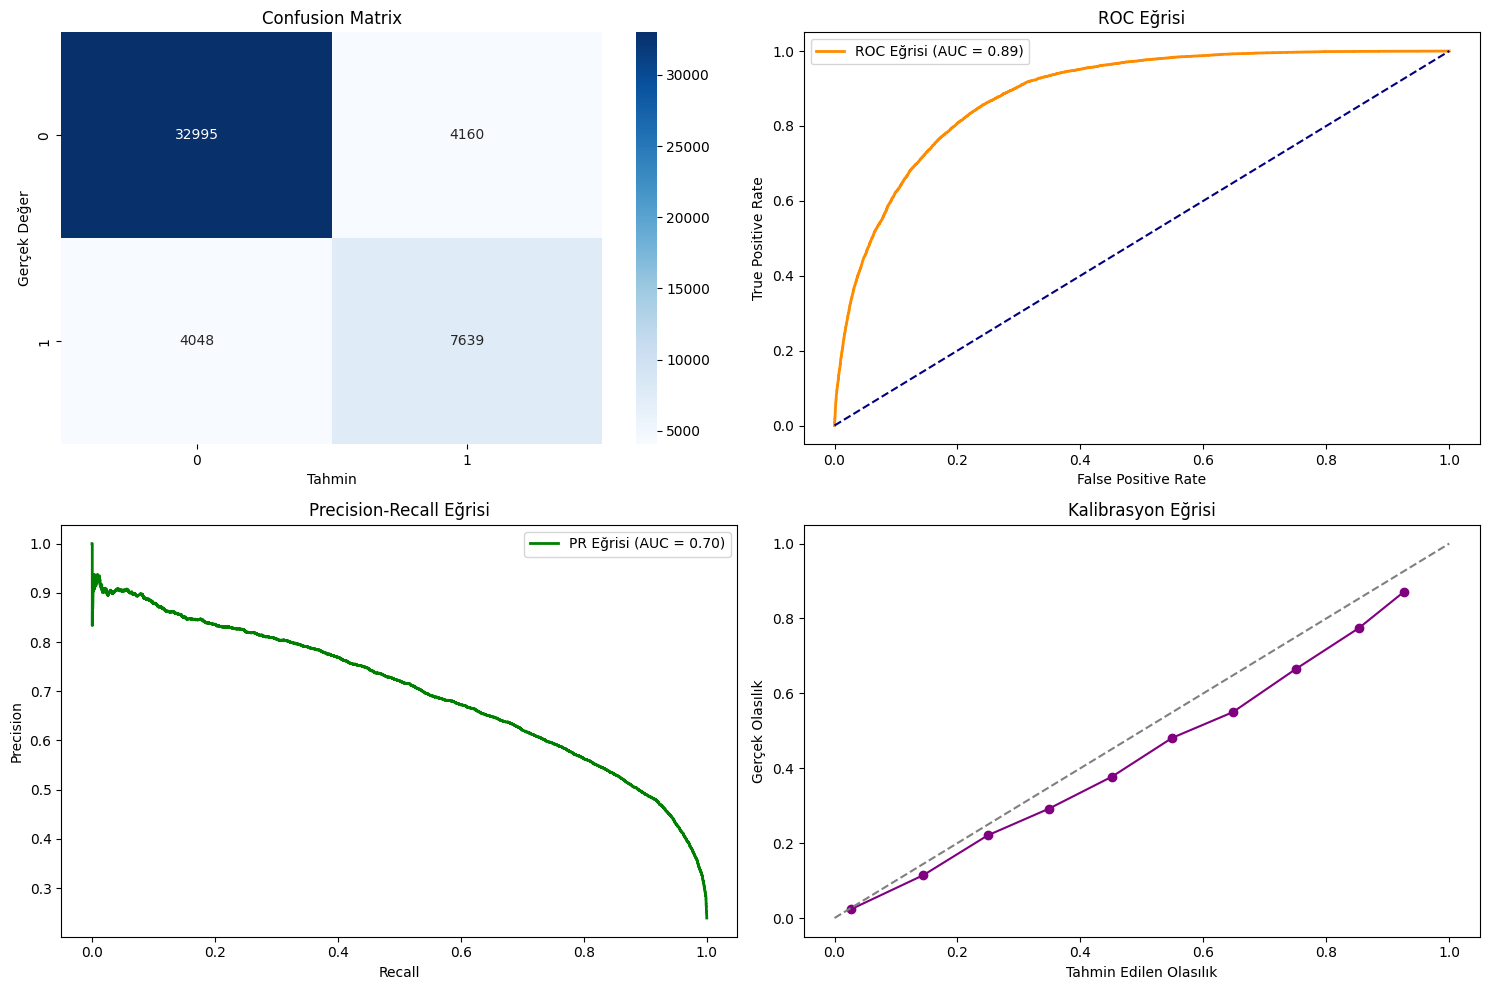


race için Performans Metrikleri:

Performans Metrikleri:
accuracy: 0.8319
balanced_accuracy: 0.7708
matthews_corr: 0.5399
precision: 0.6474
recall: 0.6536
f1: 0.6505
auc: 0.8873
log_loss: 0.3546
brier_score: 0.1147

Performans Grafikleri:


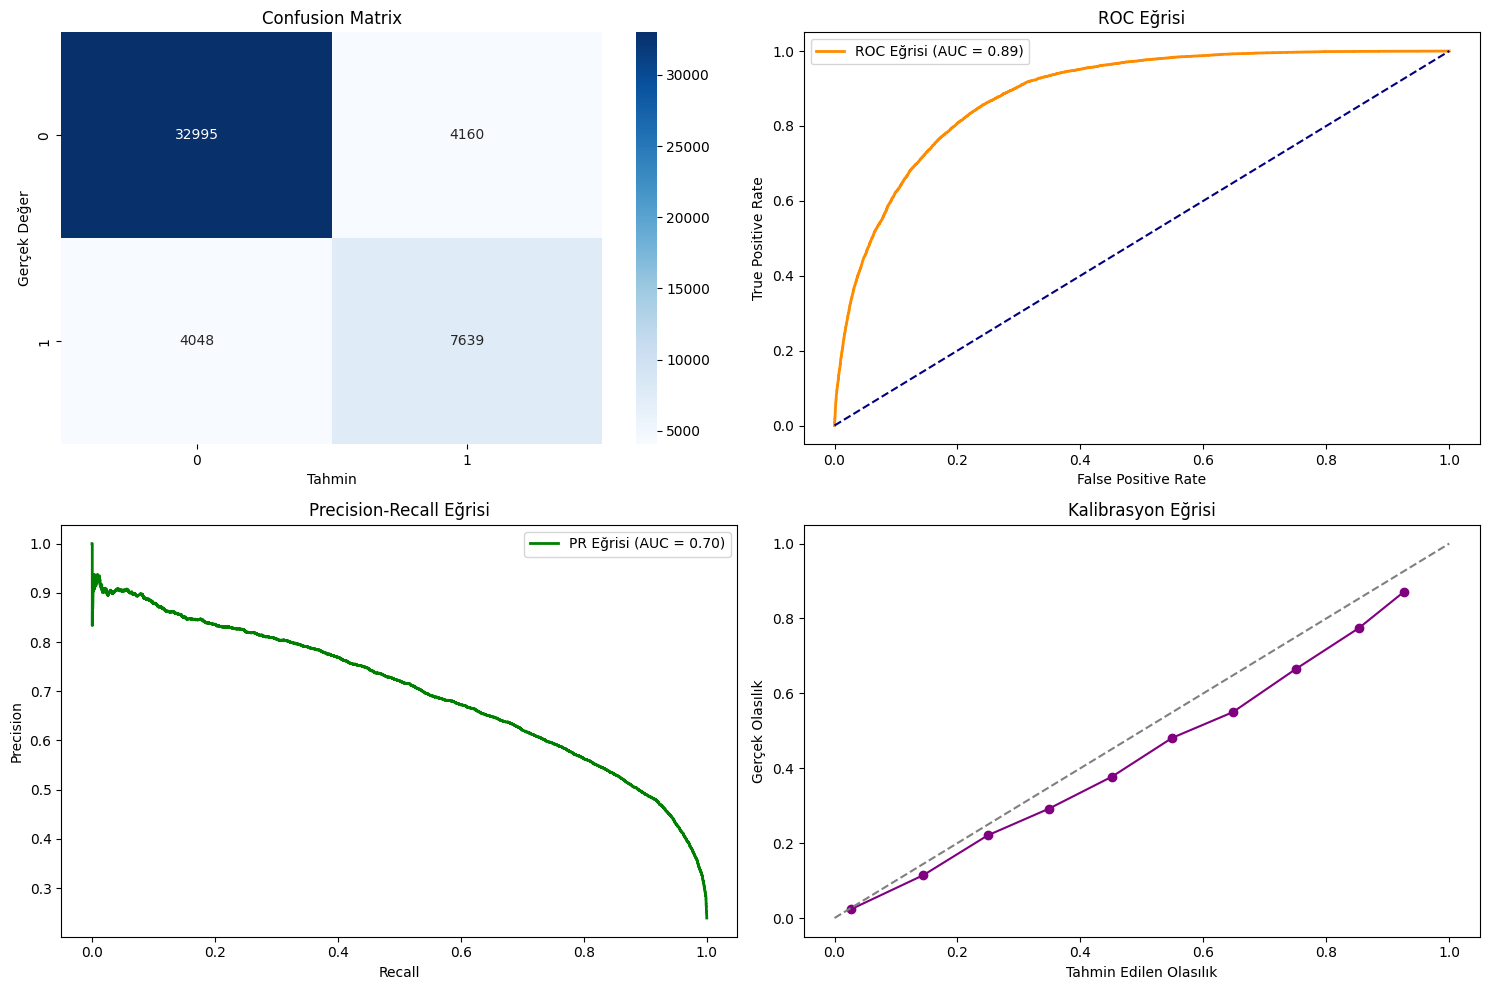


age için Performans Metrikleri:

Performans Metrikleri:
accuracy: 0.8319
balanced_accuracy: 0.7708
matthews_corr: 0.5399
precision: 0.6474
recall: 0.6536
f1: 0.6505
auc: 0.8873
log_loss: 0.3546
brier_score: 0.1147

Performans Grafikleri:


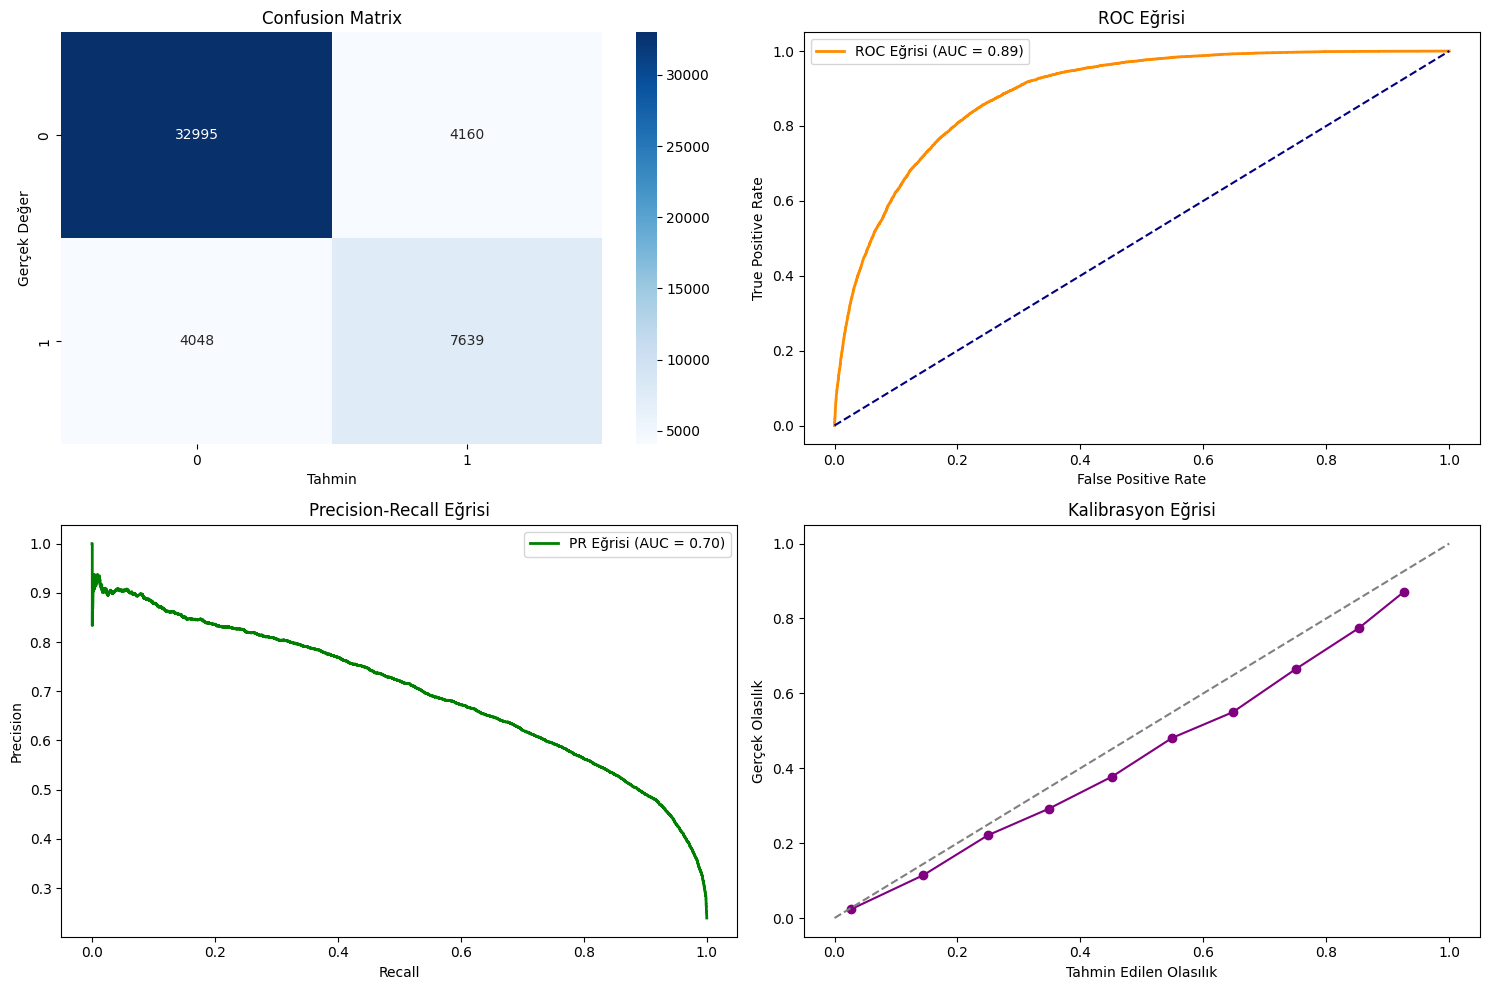

In [25]:
# Sonuçları değerlendirme kısmında:
print("\nGenel Model Performansı:")
for ozellik in hassas_ozellikler:
    print(f"\n{ozellik} için Performans Metrikleri:")
    
    y_true = y
    y_pred = predictions[ozellik]
    y_proba = probabilities[ozellik]
    
    # Tüm metrikleri hesapla ve göster
    metrics = hesapla_performans_metrikleri(y_true, y_pred, y_proba)
    print("\nPerformans Metrikleri:")
    for metric_name, value in metrics.items():
        print(f"{metric_name}: {value:.4f}")
    
    # Görselleştirmeleri göster
    print("\nPerformans Grafikleri:")
    gorsellestir_performans(y_true, y_pred, y_proba)

In [26]:
fairness_sonuclari = {}
grup_sonuclari = {}

for ozellik in hassas_ozellikler:
    print(f"\n{ozellik} için Fairness Metrikleri:")
    fairness_sonuclari[ozellik] = hesapla_fairness_metrikleri(X_df, y, predictions[ozellik], ozellik)
    print(pd.Series(fairness_sonuclari[ozellik]))
    
    print(f"\n{ozellik} için Grup Metrikleri:")
    grup_sonuclari[ozellik] = hesapla_grup_metrikleri(X_df, y, predictions[ozellik], ozellik)
    print(pd.DataFrame(grup_sonuclari[ozellik]).T)

# Cinsiyet için
    # Disperate Impact çok düşük(0.24): Kadınlar aleyhine ciddi bir yanlılık var
    # Statistical Parity Difference çok düşük(-0.25): Erkeklere daha fazla pozitif tahmin
    # Equal Oppotunity Difference çok düşük(-0.21): Fırsat eşitsizliği mevcut

# Irk için:
    # Disperate Impact düşük(0.29): Azınlık grupları aleyhine yanlılık
    # Equal Oppurtinaty farkı yüksek (-0.30): Önemli fırsat eşitsizliği

# Yaş için:
    # Yaş grupları arasında belirgin farklılıklar var
    # Genç yaş arasında pozitif tahmin oranı çok düşük

# Genel olarak modelin önemli fairness sorunları olduğunu görebiliyoruz



sex için Fairness Metrikleri:
disparate_impact          0.238936
statistical_parity       -0.245895
equal_opportunity_diff   -0.206680
average_odds_diff        -0.171949
theil_index               0.115514
dtype: float64

sex için Grup Metrikleri:
            boyut      oran  accuracy  positive_rate
grup_0.0  16192.0  0.331518  0.918046       0.077199
grup_1.0  32650.0  0.668482  0.789250       0.323093

race için Fairness Metrikleri:
disparate_impact          0.293810
statistical_parity       -0.194330
equal_opportunity_diff   -0.298955
average_odds_diff        -0.194007
theil_index               0.115514
dtype: float64

race için Grup Metrikleri:
            boyut      oran  accuracy  positive_rate
grup_0.0    470.0  0.009623  0.887234       0.080851
grup_1.0   1519.0  0.031100  0.812377       0.275181
grup_2.0   4685.0  0.095922  0.902668       0.093917
grup_3.0    406.0  0.008313  0.899015       0.096059
grup_4.0  41762.0  0.855043  0.823452       0.260141

age için Fairness Metrik

In [27]:
sonuclar = {
    'cv_results': cv_results,
    'predictions': predictions,
    'probabilities': probabilities,
    'fairness_sonuclari': fairness_sonuclari,
    'grup_sonuclari': grup_sonuclari,
    'hassas_ozellikler': hassas_ozellikler,
    'feature_names': feature_names
}

with open('fairness_cv_results.pkl', 'wb') as f:
    pickle.dump(sonuclar, f)

print("\nSonuçlar kaydedildi.")


Sonuçlar kaydedildi.
